# Iris Flower Classification
**CodeAlpha Data Science Internship — Task 1**

- **Student:** Nour Ali Mohamed
- **Student ID:** CA/DF1/414910
- **Domain:** Data Science

## 1. Project Introduction

### Overview
This project builds a supervised machine-learning classifier that predicts an Iris flower species from four measurements: sepal length, sepal width, petal length, and petal width.

### Objectives
- Inspect and understand the supplied dataset before modeling.
- Explore class balance and relationships among flower measurements.
- Train a reproducible classification model with Scikit-learn.
- Evaluate predictions on a held-out test set and demonstrate a new prediction.

### Classification problem
Each row represents one flower. The target is its species, one of **Setosa**, **Versicolor**, or **Virginica**. The task is multi-class classification because the model chooses among three possible labels.

## 2. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 3. Load the Dataset

The notebook expects the supplied CSV file at `dataset/Iris.csv`, relative to this notebook. The dataset is inspected before selecting features or applying preprocessing.

In [2]:
DATASET_PATH = Path("dataset") / "Iris.csv"
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_PATH.resolve()}. "
        "Place the supplied Iris.csv file in the notebook's dataset folder."
    )

iris_data = pd.read_csv(DATASET_PATH)

display(iris_data.head())
display(iris_data.tail())
print(f"Dataset dimensions: {iris_data.shape[0]} rows × {iris_data.shape[1]} columns")
print("\nColumn names:")
print(iris_data.columns.tolist())
print("\nData types:")
display(iris_data.dtypes.to_frame("data_type"))

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


Dataset dimensions: 150 rows × 6 columns

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Data types:


,data_type
Id,int64
SepalLengthCm,float64
SepalWidthCm,float64
PetalLengthCm,float64
PetalWidthCm,float64
Species,object


## 4. Data Exploration

In [3]:
print("Descriptive statistics:")
display(iris_data.describe(include="all").T)

print("Missing values per column:")
display(iris_data.isna().sum().to_frame("missing_values"))

duplicate_count = int(iris_data.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count}")

target_column = "Species"
if target_column not in iris_data.columns:
    raise KeyError(f"Expected target column '{target_column}' was not found.")

print("Species distribution:")
display(iris_data[target_column].value_counts().rename_axis("species").to_frame("count"))

print("Unique species labels:")
print(sorted(iris_data[target_column].dropna().unique().tolist()))

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,150.0,NaN,NaN,NaN,75.5,43.445368,1.0,38.25,75.5,112.75,150.0
SepalLengthCm,150.0,NaN,NaN,NaN,5.843333,0.828066,4.3,5.1,5.8,6.4,7.9
SepalWidthCm,150.0,NaN,NaN,NaN,3.054,0.433594,2.0,2.8,3.0,3.3,4.4
PetalLengthCm,150.0,NaN,NaN,NaN,3.758667,1.76442,1.0,1.6,4.35,5.1,6.9
PetalWidthCm,150.0,NaN,NaN,NaN,1.198667,0.763161,0.1,0.3,1.3,1.8,2.5
Species,150,3,Iris-setosa,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values per column:


,missing_values
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


Exact duplicate rows: 0
Species distribution:


,count
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


Unique species labels:
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


In [4]:
# Inspect the identifier column before excluding it from model features.
if "Id" in iris_data.columns:
    print(
        "The 'Id' column is a unique row identifier "
        f"({iris_data['Id'].nunique()} unique values for {len(iris_data)} rows), "
        "so it is excluded from modeling."
    )

The 'Id' column is a unique row identifier (150 unique values for 150 rows), so it is excluded from modeling.


## 5. Exploratory Data Analysis (EDA)

The following charts focus on class balance, feature distributions, feature relationships, and correlations. The identifier column is not treated as a measurement.

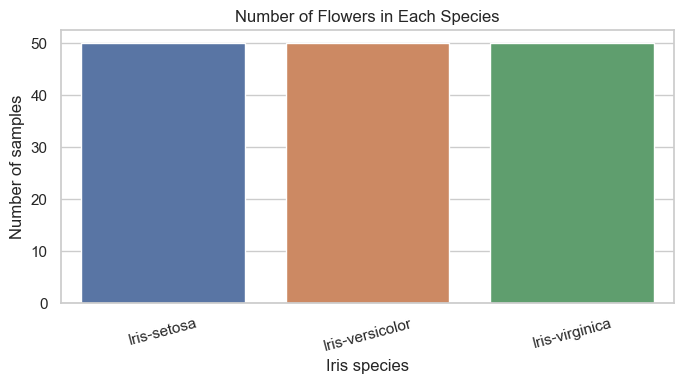

In [5]:
species_order = sorted(iris_data[target_column].dropna().unique())

plt.figure(figsize=(7, 4))
sns.countplot(data=iris_data, x=target_column, hue=target_column, order=species_order, dodge=False, legend=False)
plt.title("Number of Flowers in Each Species")
plt.xlabel("Iris species")
plt.ylabel("Number of samples")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

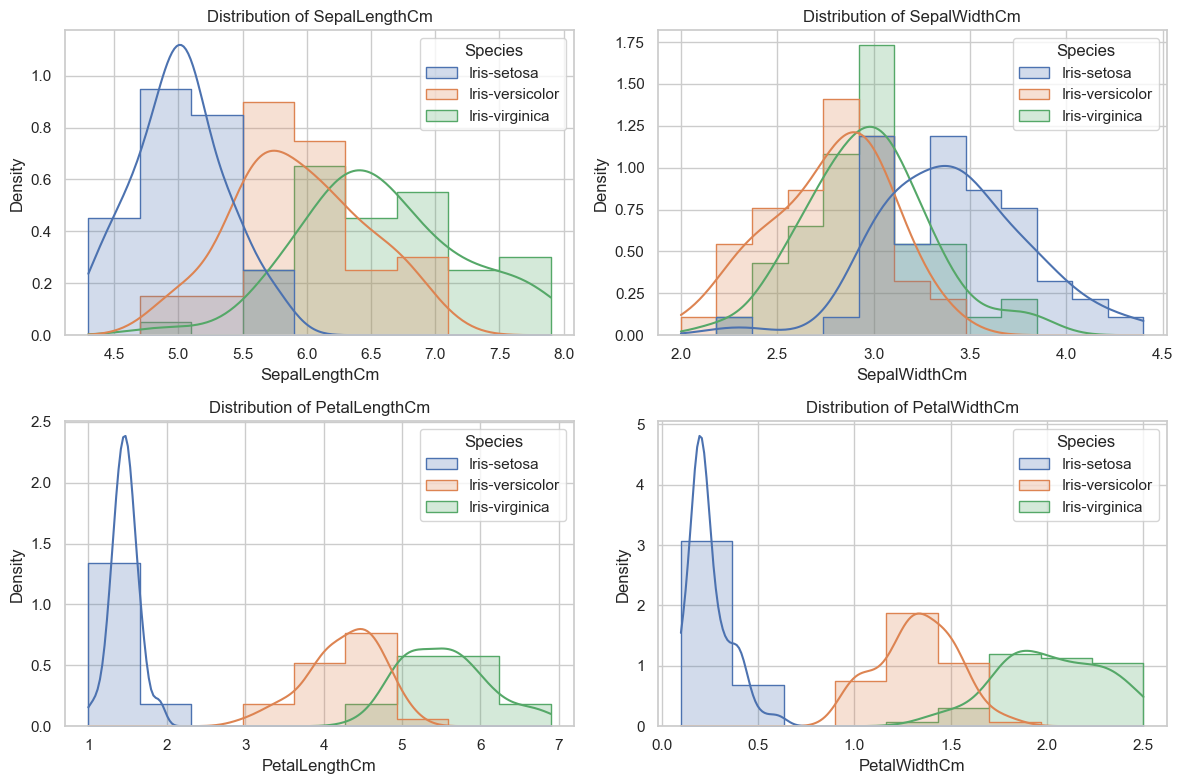

In [6]:
measurement_columns = [
    "SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"
]
missing_measurements = [column for column in measurement_columns if column not in iris_data.columns]
if missing_measurements:
    raise KeyError(f"Required measurement columns are missing: {missing_measurements}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, axis in zip(measurement_columns, axes.flat):
    sns.histplot(data=iris_data, x=column, hue=target_column, kde=True,
                 element="step", stat="density", common_norm=False, ax=axis)
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
    axis.set_ylabel("Density")
plt.tight_layout()
plt.show()

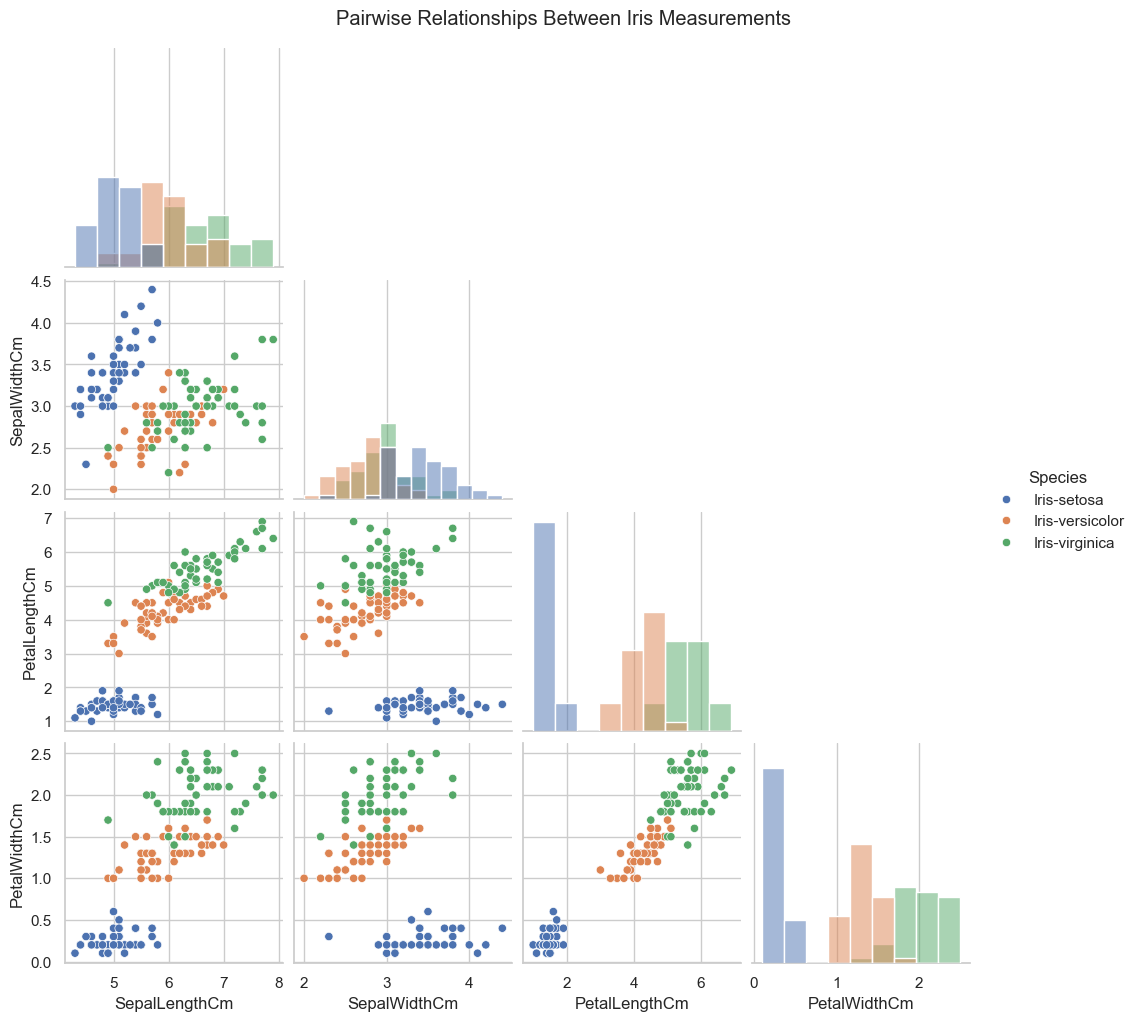

In [7]:
sns.pairplot(
    iris_data[measurement_columns + [target_column]],
    hue=target_column,
    corner=True,
    diag_kind="hist"
)
plt.suptitle("Pairwise Relationships Between Iris Measurements", y=1.02)
plt.show()

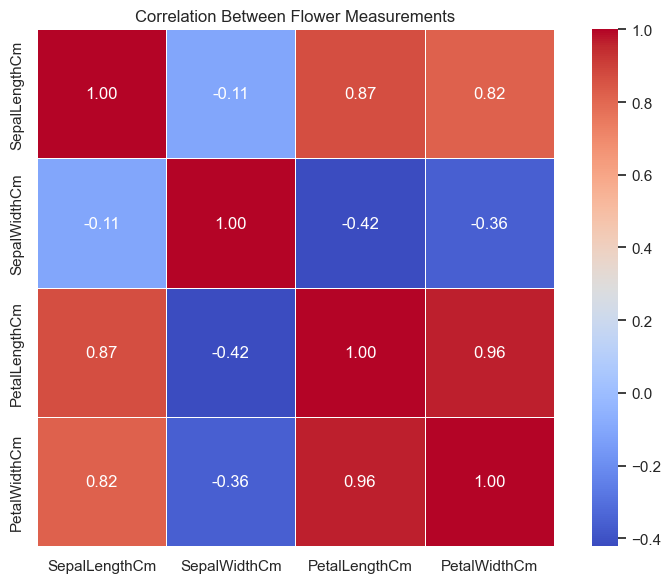

In [8]:
plt.figure(figsize=(8, 6))
correlation_matrix = iris_data[measurement_columns].corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5)
plt.title("Correlation Between Flower Measurements")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

- The target is `Species`; the four numeric flower measurements are the input features.
- The `Id` column is excluded because it is a unique identifier, not a biological measurement.
- The supplied file has no missing values and no exact duplicate rows, so no rows need to be imputed or removed.
- Species labels are already categorical strings. Scikit-learn classifiers can learn these labels directly, so a separate target encoder is unnecessary.
- A stratified train/test split preserves class proportions.
- Standardization is included inside the model pipeline. It is fitted on training data only, preventing test-set information from leaking into preprocessing.

In [9]:
model_features = measurement_columns
X = iris_data[model_features].copy()
y = iris_data[target_column].astype(str).str.replace("Iris-", "", regex=False).str.title()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training samples: 120
Testing samples: 30

Training class proportions:


,proportion
Species,
Setosa,0.333333
Versicolor,0.333333
Virginica,0.333333



Testing class proportions:


,proportion
Species,
Setosa,0.333333
Versicolor,0.333333
Virginica,0.333333


## 7. Model Development

**Chosen algorithm: Logistic Regression.** It is a well-established baseline for multi-class classification, is efficient on this small dataset, and provides an interpretable linear decision boundary. Feature scaling is useful because the measurements use the same units but have different ranges.

A five-fold stratified cross-validation score is calculated using only the training partition. The final model is then fitted on all training samples.

In [10]:
iris_classifier = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

training_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_accuracy = cross_val_score(
    iris_classifier, X_train, y_train,
    cv=training_cv, scoring="accuracy"
)

print("Training-only 5-fold cross-validation accuracy:")
print(f"Fold scores: {np.round(cv_accuracy, 4)}")
print(f"Mean accuracy: {cv_accuracy.mean():.4f} ± {cv_accuracy.std():.4f}")

iris_classifier.fit(X_train, y_train)
print("\nModel training completed.")

Training-only 5-fold cross-validation accuracy:
Fold scores: [0.9583 1.     0.9583 0.9583 0.9167]
Mean accuracy: 0.9583 ± 0.0264

Model training completed.


## 8. Model Evaluation

All reported test metrics below are calculated from predictions on the held-out test set, which was not used to fit the scaler or classifier.

In [11]:
test_predictions = iris_classifier.predict(X_test)

evaluation_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision (macro)": precision_score(y_test, test_predictions, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, test_predictions, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, test_predictions, average="macro", zero_division=0),
}
metrics_table = pd.DataFrame.from_dict(
    evaluation_metrics, orient="index", columns=["Test score"]
)
display(metrics_table.style.format("{:.4f}"))

print("Classification report:")
print(classification_report(y_test, test_predictions, digits=4, zero_division=0))

,Test score
Accuracy,0.9333
Precision (macro),0.9333
Recall (macro),0.9333
F1-score (macro),0.9333


Classification report:
              precision    recall  f1-score   support

      Setosa     1.0000    1.0000    1.0000        10
  Versicolor     0.9000    0.9000    0.9000        10
   Virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



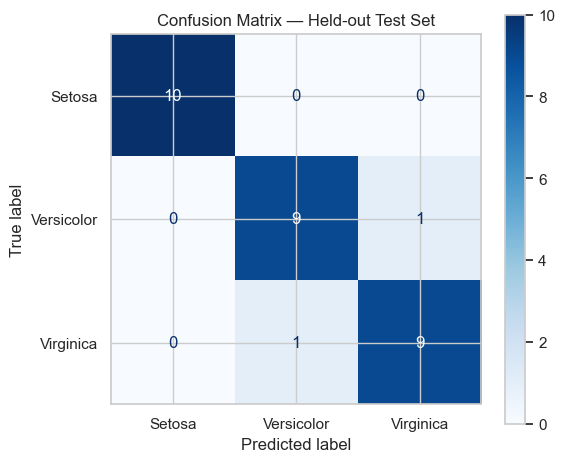

The model correctly classified 28 out of 30 test flowers.


In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=sorted(y.unique()),
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

correct_predictions = int((y_test.to_numpy() == test_predictions).sum())
print(
    f"The model correctly classified {correct_predictions} out of {len(y_test)} "
    f"test flowers."
)

## 9. Prediction Demonstration

This example uses a new set of flower measurements entered directly below. It demonstrates how to call the fitted pipeline; it is separate from the held-out test-set evaluation above.

In [13]:
sample_flower = pd.DataFrame([{
    "SepalLengthCm": 5.1,
    "SepalWidthCm": 3.5,
    "PetalLengthCm": 1.4,
    "PetalWidthCm": 0.2,
}])

sample_prediction = iris_classifier.predict(sample_flower)[0]
sample_probabilities = iris_classifier.predict_proba(sample_flower)[0]

print("Sample measurements:")
display(sample_flower)
print(f"Predicted species: {sample_prediction}")
print("Class probabilities:")
display(pd.DataFrame({
    "Species": iris_classifier.named_steps["classifier"].classes_,
    "Probability": sample_probabilities
}).sort_values("Probability", ascending=False).reset_index(drop=True))

Sample measurements:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2


Predicted species: Setosa
Class probabilities:


,Species,Probability
0,Setosa,9.813050e-01
1,Versicolor,1.869474e-02
2,Virginica,2.650772e-07


## 10. Conclusion

This project inspected the supplied Iris dataset, explored the four flower measurements, and trained a Logistic Regression classifier using a Scikit-learn pipeline. The pipeline standardizes features using training data only and predicts one of the three Iris species.

The final test accuracy, precision, recall, and F1-score are generated from the executed notebook rather than hardcoded. The confusion matrix shows which classes were correctly classified and where errors occurred.

### Key findings
- The dataset contains three Iris species and four numeric flower measurements.
- The `Id` field is an identifier and is not useful as a biological predictor.
- Petal measurements and the pairwise plots help reveal separation between species.

### Possible improvements
- Evaluate the model on a different train/test split or an external dataset.
- Compare Logistic Regression with a small number of alternatives using training-only cross-validation.
- Tune model hyperparameters while keeping the final test set untouched.

**Reproducibility:** the train/test split and cross-validation use a fixed random seed (`42`).